some trained models:

1. model_1: SquareGMM of Simon, feat=30, inflate_full=True, delta=0.005, max_feature_dim=30, max_model_dim=30, prior.gmm.max_num_cluster=30, EPOCHS=50, BATCH_SIZE=4, nlayer=4, nhead=2, lr=0.0001

2. model_2: SquareGMM of Simon, feat=30, inflate_full=True, delta=0.005, max_feature_dim=30, max_model_dim=30, prior.gmm.max_num_cluster=30, EPOCHS=50, BATCH_SIZE=4, nlayer=4, nhead=2, lr=0.0003

3. model_3: SquareGMM of Simon, feat=30, inflate_full=True, delta=0.005, max_feature_dim=30, max_model_dim=30, prior.gmm.max_num_cluster=30, EPOCHS=50, BATCH_SIZE=4, nlayer=4, nhead=2, lr=0.0006

4. model_4: SquareGMM of Simon, feat=30, inflate_full=True, delta=0.005, max_feature_dim=30, max_model_dim=30, prior.gmm.max_num_cluster=30, EPOCHS=50, BATCH_SIZE=4, nlayer=4, nhead=2, lr=0.001

5. model_5: SquareGMM of Simon, feat=30, inflate_full=True, delta=0.005, max_feature_dim=30, max_model_dim=30, prior.gmm.max_num_cluster=30, EPOCHS=50, BATCH_SIZE=4, nlayer=4, nhead=2, lr=0.003

6. model_6: SquareGMM of Simon, feat=30, inflate_full=True, delta=0.005, max_feature_dim=30, max_model_dim=30, prior.gmm.max_num_cluster=30, EPOCHS=50, BATCH_SIZE=4, nlayer=4, nhead=2, lr=0.006

7. model_7: SquareGMM of Simon, feat=30, inflate_full=True, delta=0.005, max_feature_dim=30, max_model_dim=30, prior.gmm.max_num_cluster=30, EPOCHS=50, BATCH_SIZE=4, nlayer=4, nhead=2, lr=0.01



https://neptune.ai/blog/f1-score-accuracy-roc-auc-pr-auc

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import torch

In [2]:
# paths of models
model_1_dir = "../results/adbench/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0001.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_2_dir = "../results/adbench/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0003.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_3_dir = "../results/adbench/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0006.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_4_dir = "../results/adbench/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_5_dir = "../results/adbench/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.003.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_6_dir = "../results/adbench/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.006.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_7_dir = "../results/adbench/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.01.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/train_seed=0.transform=quantile.feat_truncation=subsampling"



In [3]:
# paths of models
model_1_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0001.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/train_val_loss.pickle"
model_2_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0003.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/train_val_loss.pickle"
model_3_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0006.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/train_val_loss.pickle"
model_4_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/train_val_loss.pickle"
model_5_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.003.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/train_val_loss.pickle"
model_6_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.006.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/train_val_loss.pickle"
model_7_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.01.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/train_val_loss.pickle"



### 1. Model_1

In [4]:
model_1_aucroc_scores = []
model_1_aucpr_scores = []
model_1_f1_scores = []
datasets_name = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_1_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_1_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_1_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_1_f1_scores.append(f1)

# compute average scores of all datasets
model_1_avg_aucroc = sum(model_1_aucroc_scores) / len(model_1_aucroc_scores)
model_1_avg_aucpr = sum(model_1_aucpr_scores) / len(model_1_aucpr_scores)
model_1_avg_f1 = sum(model_1_f1_scores) / len(model_1_f1_scores)

print(f"number of datasets: {len(model_1_aucroc_scores)}")
print(f"Average aucroc: {model_1_avg_aucroc}")
print(f"Average aucpr: {model_1_avg_aucpr}")
print(f"Average f1: {model_1_avg_f1}")

number of datasets: 121
Average aucroc: 0.7445487907602588
Average aucpr: 0.42436454224567843
Average f1: 0.4309873328564746


In [5]:
# Analyzing top 10 Datasets with the worst aucroc scores
model_1_dict = {'dataset': datasets_name, 'aucroc': model_1_aucroc_scores, 'aucpr': model_1_aucpr_scores, 'f1': model_1_f1_scores}
model_1_df = pd.DataFrame(model_1_dict)
model_1_top10_worst_aucroc = model_1_df.sort_values(by='aucroc', ascending=True).head(10)
model_1_top10_worst_aucroc

,dataset,aucroc,aucpr,f1
67,3_backdoor,0.269022,0.073730,0.092834
111,8_celeba,0.299113,0.027536,0.016023
83,36_speech,0.392294,0.025689,0.000000
59,47_yeast,0.475220,0.496559,0.479290
118,CIFAR10_5,0.475376,0.094876,0.095057
57,20news_2,0.475800,0.092035,0.088710
26,CIFAR10_3,0.494195,0.098592,0.091255
46,MNIST-C_identity,0.495849,0.095483,0.080000
53,imdb,0.499301,0.090808,0.064000
103,MNIST-C_rotate,0.509275,0.105148,0.138000


### 2. Model_2

In [6]:
model_2_aucroc_scores = []
model_2_aucpr_scores = []
model_2_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_2_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_2_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_2_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_2_f1_scores.append(f1)

# compute average scores of all datasets
model_2_avg_aucroc = sum(model_2_aucroc_scores) / len(model_2_aucroc_scores)
model_2_avg_aucpr = sum(model_2_aucpr_scores) / len(model_2_aucpr_scores)
model_2_avg_f1 = sum(model_2_f1_scores) / len(model_2_f1_scores)

print(f"number of datasets: {len(model_2_aucroc_scores)}")
print(f"Average aucroc: {model_2_avg_aucroc}")
print(f"Average aucpr: {model_2_avg_aucpr}")
print(f"Average f1: {model_2_avg_f1}")

number of datasets: 121
Average aucroc: 0.7462601143023361
Average aucpr: 0.4336617472042864
Average f1: 0.43017390215662576


### 4. Model_3

In [7]:
model_3_aucroc_scores = []
model_3_aucpr_scores = []
model_3_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_3_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_3_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_3_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_3_f1_scores.append(f1)

# compute average scores of all datasets
model_3_avg_aucroc = sum(model_3_aucroc_scores) / len(model_3_aucroc_scores)
model_3_avg_aucpr = sum(model_3_aucpr_scores) / len(model_3_aucpr_scores)
model_3_avg_f1 = sum(model_3_f1_scores) / len(model_3_f1_scores)

print(f"number of datasets: {len(model_3_aucroc_scores)}")
print(f"Average aucroc: {model_3_avg_aucroc}")
print(f"Average aucpr: {model_3_avg_aucpr}")
print(f"Average f1: {model_3_avg_f1}")

number of datasets: 121
Average aucroc: 0.7406016027250094
Average aucpr: 0.42225955033671037
Average f1: 0.42127879616566183


### 4. Model_4

In [8]:
model_4_aucroc_scores = []
model_4_aucpr_scores = []
model_4_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_4_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_4_f1_scores.append(f1)

# compute average scores of all datasets
model_4_avg_aucroc = sum(model_4_aucroc_scores) / len(model_4_aucroc_scores)
model_4_avg_aucpr = sum(model_4_aucpr_scores) / len(model_4_aucpr_scores)
model_4_avg_f1 = sum(model_4_f1_scores) / len(model_4_f1_scores)

print(f"number of datasets: {len(model_4_aucroc_scores)}")
print(f"Average aucroc: {model_4_avg_aucroc}")
print(f"Average aucpr: {model_4_avg_aucpr}")
print(f"Average f1: {model_4_avg_f1}")

number of datasets: 121
Average aucroc: 0.7336133358147777
Average aucpr: 0.4012960318426039
Average f1: 0.40111275677258895


### 5. model_5

In [9]:
model_5_aucroc_scores = []
model_5_aucpr_scores = []
model_5_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_5_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_5_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_5_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_5_f1_scores.append(f1)

# compute average scores of all datasets
model_5_avg_aucroc = sum(model_5_aucroc_scores) / len(model_5_aucroc_scores)
model_5_avg_aucpr = sum(model_5_aucpr_scores) / len(model_5_aucpr_scores)
model_5_avg_f1 = sum(model_5_f1_scores) / len(model_5_f1_scores)

print(f"number of datasets: {len(model_5_aucroc_scores)}")
print(f"Average aucroc: {model_5_avg_aucroc}")
print(f"Average aucpr: {model_5_avg_aucpr}")
print(f"Average f1: {model_5_avg_f1}")

number of datasets: 121
Average aucroc: 0.7501703307116786
Average aucpr: 0.4197472683315578
Average f1: 0.42028147056643367


### 6. model_6

In [10]:
model_6_aucroc_scores = []
model_6_aucpr_scores = []
model_6_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_6_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_6_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_6_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_6_f1_scores.append(f1)

# compute average scores of all datasets
model_6_avg_aucroc = sum(model_6_aucroc_scores) / len(model_6_aucroc_scores)
model_6_avg_aucpr = sum(model_6_aucpr_scores) / len(model_6_aucpr_scores)
model_6_avg_f1 = sum(model_6_f1_scores) / len(model_6_f1_scores)

print(f"number of datasets: {len(model_6_aucroc_scores)}")
print(f"Average aucroc: {model_6_avg_aucroc}")
print(f"Average aucpr: {model_6_avg_aucpr}")
print(f"Average f1: {model_6_avg_f1}")

number of datasets: 121
Average aucroc: 0.6938730302039094
Average aucpr: 0.38231449246323307
Average f1: 0.374980994878364


### 7. model_7

In [11]:
model_7_aucroc_scores = []
model_7_aucpr_scores = []
model_7_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_7_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_7_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_7_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_7_f1_scores.append(f1)

# compute average scores of all datasets
model_7_avg_aucroc = sum(model_7_aucroc_scores) / len(model_7_aucroc_scores)
model_7_avg_aucpr = sum(model_7_aucpr_scores) / len(model_7_aucpr_scores)
model_7_avg_f1 = sum(model_7_f1_scores) / len(model_7_f1_scores)

print(f"number of datasets: {len(model_7_aucroc_scores)}")
print(f"Average aucroc: {model_7_avg_aucroc}")
print(f"Average aucpr: {model_7_avg_aucpr}")
print(f"Average f1: {model_7_avg_f1}")

number of datasets: 121
Average aucroc: 0.5
Average aucpr: 0.16736306015990665
Average f1: 0.16524718696953253


In [12]:
# sns.barplot(data=summary_results, x="models", y="average_aucroc")
# plt.ylim(0,1)
# plt.title("Average AUCROC Comparison Across Models")
# plt.xticks(rotation=45, ha="right")
# plt.show()

## Plot losses

In [13]:
# load pickel
#model 1
with open(model_1_dir_loss, "rb") as f:
    data = pickle.load(f)
train_loss_1 = data["train_loss"]
val_loss_1 = data["val_loss"]
train_time_1 = data['train_time']

#model2
with open(model_2_dir_loss, "rb") as f:
    data2 = pickle.load(f)
train_loss_2 = data2["train_loss"]
val_loss_2 = data2["val_loss"]
train_time_2 = data2['train_time']

#model3
with open(model_3_dir_loss, "rb") as f:
    data3 = pickle.load(f)
train_loss_3 = data3["train_loss"]
val_loss_3 = data3["val_loss"]
train_time_3 = data3['train_time']

#model4
with open(model_4_dir_loss, "rb") as f:
    data4 = pickle.load(f)
train_loss_4 = data4["train_loss"]
val_loss_4 = data4["val_loss"]
train_time_4 = data4['train_time']

#model5
with open(model_5_dir_loss, "rb") as f:
    data5 = pickle.load(f)
train_loss_5 = data5["train_loss"]
val_loss_5 = data5["val_loss"]
train_time_5 = data5['train_time']

#model6
with open(model_6_dir_loss, "rb") as f:
    data6 = pickle.load(f)
train_loss_6 = data6["train_loss"]
val_loss_6 = data6["val_loss"]
train_time_6 = data6['train_time']

#model7
with open(model_7_dir_loss, "rb") as f:
    data7 = pickle.load(f)
train_loss_7 = data7["train_loss"]
val_loss_7 = data7["val_loss"]
train_time_7 = data7['train_time']

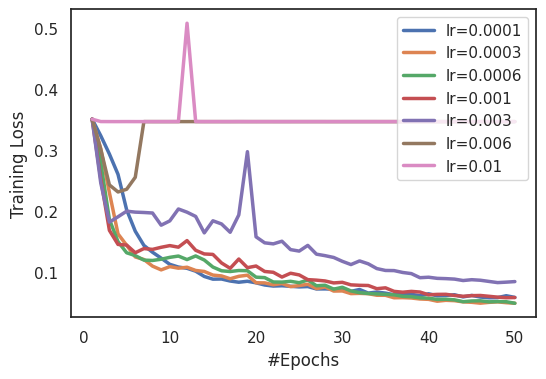

In [29]:
# plot
epochs = range(1, len(train_loss_1) + 1)
# seaborn style
sns.set_theme(style="white")  # darkgrid
plt.figure(figsize=(6,4))
plt.plot(epochs, train_loss_1, label="lr=0.0001", linewidth=2.5)
plt.plot(epochs, train_loss_2, label="lr=0.0003", linewidth=2.5)
plt.plot(epochs, train_loss_3, label="lr=0.0006", linewidth=2.5)
plt.plot(epochs, train_loss_4, label="lr=0.001", linewidth=2.5)
plt.plot(epochs, train_loss_5, label="lr=0.003", linewidth=2.5)
plt.plot(epochs, train_loss_6, label="lr=0.006", linewidth=2.5)
plt.plot(epochs, train_loss_7, label="lr=0.01", linewidth=2.5)

plt.xlabel("#Epochs")
plt.ylabel("Training Loss")
#plt.title("CoTrain Loss")
plt.legend()
#plt.grid(True)
plt.savefig('lr_train_loss.png', dpi=300, bbox_inches='tight')
plt.show()

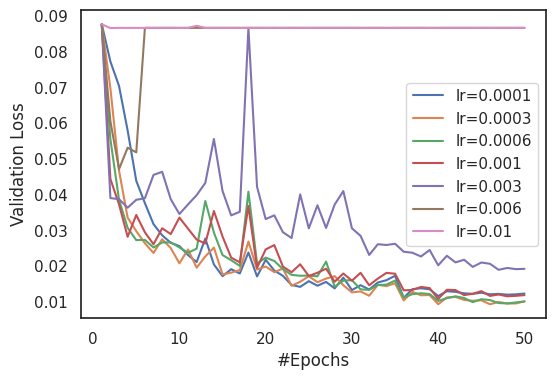

In [17]:
# plot
epochs = range(1, len(train_loss_1) + 1)
# seaborn style
sns.set_theme(style="white")  # darkgrid
plt.figure(figsize=(6,4))
plt.plot(epochs, val_loss_1, label="lr=0.0001")
plt.plot(epochs, val_loss_2, label="lr=0.0003")
plt.plot(epochs, val_loss_3, label="lr=0.0006")
plt.plot(epochs, val_loss_4, label="lr=0.001")
plt.plot(epochs, val_loss_5, label="lr=0.003")
plt.plot(epochs, val_loss_6, label="lr=0.006")
plt.plot(epochs, val_loss_7, label="lr=0.01")

plt.xlabel("#Epochs")
plt.ylabel("Validation Loss")
#plt.title("CoTrain Loss")
plt.legend()
#plt.grid(True)

plt.show()

## Visualization

In [14]:
models = ['Model_1', 'Model_2', 'Model_3', 'Model_4', 'Model_5', 'Model_6', 'Model_7']
learning_rate = ['0.0001', '0.0003', '0.0006', '0.001', '0.003', '0.006', '0.01']
avg_aucroc_scores = [round(model_1_avg_aucroc, 3), round(model_2_avg_aucroc, 3), round(model_3_avg_aucroc, 3), round(model_4_avg_aucroc, 3), round(model_5_avg_aucroc, 3), round(model_6_avg_aucroc, 3), round(model_7_avg_aucroc, 3)]
avg_aucpr_scores = [round(model_1_avg_aucpr, 3), round(model_2_avg_aucpr, 3), round(model_3_avg_aucpr, 3), round(model_4_avg_aucpr, 3), round(model_5_avg_aucpr, 3), round(model_6_avg_aucpr, 3), round(model_7_avg_aucpr, 3)]
avg_f1_scores = [round(model_1_avg_f1, 3), round(model_2_avg_f1, 3), round(model_3_avg_f1, 3), round(model_4_avg_f1, 3), round(model_5_avg_f1, 3), round(model_6_avg_f1, 3), round(model_7_avg_f1, 3)]
train_time = [round(train_time_1, 3), round(train_time_2, 3), round(train_time_3, 3), round(train_time_4, 3), round(train_time_5, 3), round(train_time_6, 3), round(train_time_7, 3)]
summary_dict = {'models': models, 'learning_rate': learning_rate, 'average_aucroc': avg_aucroc_scores, 'average_aucpr': avg_aucpr_scores, 'average_f1': avg_f1_scores, 'train_time': train_time}

In [15]:
summary_results = pd.DataFrame(summary_dict)

In [16]:
summary_results

,models,learning_rate,average_aucroc,average_aucpr,average_f1,train_time
0,Model_1,0.0001,0.745,0.424,0.431,7387.166
1,Model_2,0.0003,0.746,0.434,0.430,7439.068
2,Model_3,0.0006,0.741,0.422,0.421,7463.262
3,Model_4,0.001,0.734,0.401,0.401,7993.567
4,Model_5,0.003,0.750,0.420,0.420,7703.138
5,Model_6,0.006,0.694,0.382,0.375,7471.932
6,Model_7,0.01,0.500,0.167,0.165,7393.906


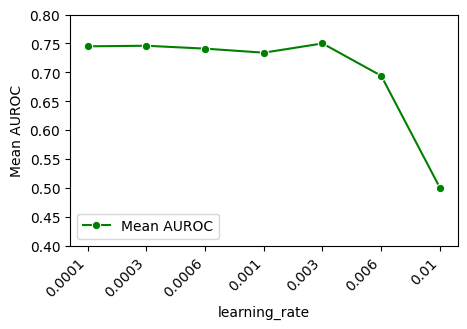

In [39]:
plt.figure(figsize=(5, 3))
sns.lineplot(data=summary_results, x="learning_rate", y="average_aucroc", marker='o', label='Mean AUROC', color='green')
# for x, y in zip(range(len(summary_results['learning_rate'])), summary_results['average_aucroc']):
#     plt.text(x, y, f'{y:.3f}', fontsize=8, ha='center', va='bottom', color='m')
plt.ylim(0,1)
plt.ylabel('Mean AUROC')
#plt.title("Mean AUCROC comparison across models")
plt.xticks(rotation=45, ha="right")
plt.ylim([0.4, 0.8])
#plt.savefig('2_lr_mean_auroc.png', dpi=300, bbox_inches='tight')
plt.show()

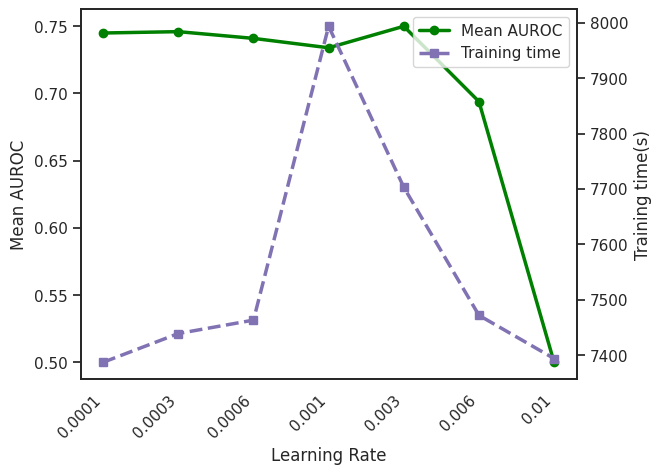

In [ ]:
x = summary_results['learning_rate']  

fig, ax1 = plt.subplots()

# First axis (AUROC)
line1, = ax1.plot(x, summary_results['average_aucroc'], marker='o', label='Mean AUROC', color='green', linewidth=2.5)
ax1.set_xlabel('Learning Rate')
ax1.set_ylabel('Mean AUROC')
plt.xticks(rotation=45, ha="right")
#plt.legend()

# Second axis (Train Time)
ax2 = ax1.twinx()
line2, = ax2.plot(x, summary_results['train_time'], marker='s', label='Training time', color='m', linestyle='dashed', linewidth=2.5)
ax2.set_ylabel('Training time(s)')

lines = [line1, line2]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

#plt.title('Mean AUROC vs Train Time')
#plt.savefig('lr_mean_auroc.png', dpi=300, bbox_inches='tight')
#plt.legend()
plt.show()

# check last_lr

In [29]:
model_1_best_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0001.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/best.ckpt"
model_2_best_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0003.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/best.ckpt"
model_3_best_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.0006.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/best.ckpt"
model_4_best_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/best.ckpt"
model_5_best_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.003.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/best.ckpt"
model_6_best_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.006.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/best.ckpt"
model_7_best_dir_loss = "../ckpt/dataSGMM.context5000.feat30.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.01.emb256.hdim512.nhead2.nlayer4.ndevice1.numclusters30/seed0/best.ckpt"



In [31]:
# model_1
m1_ckpt_best = torch.load(model_1_best_dir_loss, map_location="cpu")
m1_train_loss = m1_ckpt_best["train_losses"]
m1_val_loss =m1_ckpt_best["val_losses"]
m1_last_lr = m1_ckpt_best["lr_schedulers"][0]['_last_lr']

# model_2
m2_ckpt_best = torch.load(model_2_best_dir_loss, map_location="cpu")
m2_last_lr = m2_ckpt_best["lr_schedulers"][0]['_last_lr']

# model_3
m3_ckpt_best = torch.load(model_3_best_dir_loss, map_location="cpu")
m3_last_lr = m3_ckpt_best["lr_schedulers"][0]['_last_lr']

# model_3
m3_ckpt_best = torch.load(model_3_best_dir_loss, map_location="cpu")
m3_last_lr = m3_ckpt_best["lr_schedulers"][0]['_last_lr']

# model_4
m4_ckpt_best = torch.load(model_4_best_dir_loss, map_location="cpu")
m4_last_lr = m4_ckpt_best["lr_schedulers"][0]['_last_lr']

# model_5
m5_ckpt_best = torch.load(model_5_best_dir_loss, map_location="cpu")
m5_last_lr = m5_ckpt_best["lr_schedulers"][0]['_last_lr']

# model_6
m6_ckpt_best = torch.load(model_6_best_dir_loss, map_location="cpu")
m6_last_lr = m6_ckpt_best["lr_schedulers"][0]['_last_lr']

# model_7
m7_ckpt_best = torch.load(model_7_best_dir_loss, map_location="cpu")
m7_last_lr = m7_ckpt_best["lr_schedulers"][0]['_last_lr']

In [32]:
last_lrs = [m1_last_lr, m2_last_lr, m3_last_lr, m4_last_lr, m5_last_lr, m6_last_lr, m7_last_lr]
last_lrs

[[1.5299867030334814e-06],
 [0.0],
 [0.0],
 [1.7077534966650766e-06],
 [2.0458044895916516e-05],
 [0.002],
 [1.7077534966650764e-05]]